# Búsqueda en profundidad (DFS)

Explora un grafo avanzando todo lo posible por cada rama antes de retroceder. Se implementa con recursión o con una pila. Cuesta $O(V + E)$.

Los grafos se representan con listas de adyacencia: un diccionario `nodo → vecinos`.

## 1. DFS recursivo

Devolver el orden en que DFS visita los nodos desde un origen.

In [1]:
grafo = {
    "A": ["B", "C"],
    "B": ["D", "E"],
    "C": ["F"],
    "D": [],
    "E": ["F"],
    "F": [],
}

def dfs(grafo, nodo, visitados=None):
    if visitados is None:
        visitados = []
    visitados.append(nodo)
    for vecino in grafo[nodo]:
        if vecino not in visitados:
            dfs(grafo, vecino, visitados)
    return visitados

print(dfs(grafo, "A"))

['A', 'B', 'D', 'E', 'F', 'C']


## 2. DFS iterativo con pila

Implementar DFS sin recursión usando una pila explícita.

In [2]:
def dfs_iterativo(grafo, origen):
    visitados, pila = [], [origen]
    while pila:
        nodo = pila.pop()
        if nodo not in visitados:
            visitados.append(nodo)
            # invertidos para visitar en el mismo orden que la recursiva
            pila.extend(reversed(grafo[nodo]))
    return visitados

print(dfs_iterativo(grafo, "A"))

['A', 'B', 'D', 'E', 'F', 'C']


## 3. ¿Existe camino?

Encontrar un camino entre dos nodos con DFS (o `None` si no hay).

In [3]:
def camino(grafo, origen, destino, visitados=None):
    visitados = visitados or set()
    if origen == destino:
        return [origen]
    visitados.add(origen)
    for vecino in grafo[origen]:
        if vecino not in visitados:
            resto = camino(grafo, vecino, destino, visitados)
            if resto:
                return [origen] + resto
    return None

print(camino(grafo, "A", "F"), camino(grafo, "D", "A"))

['A', 'B', 'E', 'F'] None


## 4. Detectar ciclos

En un grafo dirigido hay un ciclo si DFS encuentra una arista hacia un nodo **gris** (empezado pero no terminado, es decir, en la pila de llamadas). Devolver un ciclo o `None` y comprobarlo con `graphlib.TopologicalSorter`, que lanza `CycleError` si no existe orden topológico. En un grafo no dirigido basta con encontrar un vecino ya visitado que no sea el padre.

In [4]:
import random
from graphlib import CycleError, TopologicalSorter

def ciclo_dirigido(grafo):
    color, pila = {n: "blanco" for n in grafo}, []

    def visita(nodo):
        color[nodo] = "gris"
        pila.append(nodo)
        for vecino in grafo[nodo]:
            if color[vecino] == "gris":
                return pila[pila.index(vecino):] + [vecino]
            if color[vecino] == "blanco":
                ciclo = visita(vecino)
                if ciclo:
                    return ciclo
        color[nodo] = "negro"
        pila.pop()
        return None

    for nodo in grafo:
        if color[nodo] == "blanco":
            ciclo = visita(nodo)
            if ciclo:
                return ciclo
    return None

def ciclo_no_dirigido(grafo):
    visitados = set()

    def visita(nodo, padre):
        visitados.add(nodo)
        for vecino in grafo[nodo]:
            if vecino != padre and (vecino in visitados or visita(vecino, nodo)):
                return True
        return False

    return any(n not in visitados and visita(n, None) for n in grafo)

def tiene_ciclo_graphlib(grafo):
    try:
        tuple(TopologicalSorter(grafo).static_order())
        return False
    except CycleError:
        return True

def grafo_aleatorio(n, p, dirigido=True):
    g = {i: [] for i in range(n)}
    for u in range(n):
        for v in range(n):
            if u != v and (dirigido or u < v) and random.random() < p:
                g[u].append(v)
                if not dirigido:
                    g[v].append(u)
    return g

con_ciclo = {**grafo, "F": ["B"]}
print(ciclo_dirigido(grafo), ciclo_dirigido(con_ciclo))

arbol = {1: [2, 3], 2: [1, 4, 5], 3: [1], 4: [2], 5: [2]}
con_ciclo_nd = {**arbol, 3: [1, 5], 5: [2, 3]}
print(ciclo_no_dirigido(arbol), ciclo_no_dirigido(con_ciclo_nd))

random.seed(4)
for _ in range(500):
    g = grafo_aleatorio(random.randint(1, 8), 0.15)
    ciclo = ciclo_dirigido(g)
    assert (ciclo is not None) == tiene_ciclo_graphlib(g)
    if ciclo:
        assert ciclo[0] == ciclo[-1] and all(b in g[a] for a, b in zip(ciclo, ciclo[1:]))

None ['B', 'E', 'F', 'B']
False True


## 5. Componentes conexas

En un grafo no dirigido, numerar las componentes conexas lanzando un DFS con pila desde cada nodo aún sin visitar. Comprobar en grafos aleatorios que dos nodos están en la misma componente si y solo si existe camino entre ellos (ejercicio 3).

In [5]:
def componentes(grafo):
    componente, actual = {}, 0
    for inicio in grafo:
        if inicio in componente:
            continue
        componente[inicio], pila = actual, [inicio]
        while pila:
            for vecino in grafo[pila.pop()]:
                if vecino not in componente:
                    componente[vecino] = actual
                    pila.append(vecino)
        actual += 1
    return componente

amistades = {
    "Ana": ["Luis"], "Luis": ["Ana", "Eva"], "Eva": ["Luis"],
    "Pau": ["Iker"], "Iker": ["Pau"],
    "Sara": [],
}
grupos = {}
for persona, c in componentes(amistades).items():
    grupos.setdefault(c, []).append(persona)
print(list(grupos.values()))

random.seed(5)
for _ in range(200):
    g = grafo_aleatorio(random.randint(1, 9), 0.2, dirigido=False)
    comp = componentes(g)
    for u in g:
        for v in g:
            assert (comp[u] == comp[v]) == (camino(g, u, v) is not None)

[['Ana', 'Luis', 'Eva'], ['Pau', 'Iker'], ['Sara']]


## 6. Laberinto en una rejilla

Generar un laberinto «perfecto» con DFS aleatorio: desde la casilla actual, abrir paso hacia un vecino sin visitar elegido al azar y retroceder cuando no quede ninguno. Resolverlo con DFS desde la esquina superior izquierda hasta la inferior derecha, comprobar que el laberinto es un árbol (conexo y sin ciclos) y dibujarlo con el camino.

Camino de 237 casillas; exploradas 464 de 479 libres


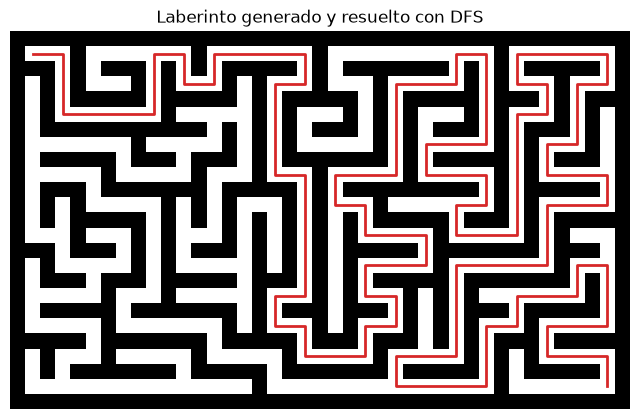

In [6]:
import matplotlib.pyplot as plt

def genera_laberinto(alto, ancho, semilla):
    rng = random.Random(semilla)
    filas, columnas = 2 * alto + 1, 2 * ancho + 1
    rejilla = [["#"] * columnas for _ in range(filas)]
    rejilla[1][1], pila = ".", [(1, 1)]
    while pila:
        f, c = pila[-1]
        # las casillas están en posiciones impares; entre dos, el muro que se abre
        vecinos = [(f + df, c + dc) for df, dc in ((0, 2), (2, 0), (0, -2), (-2, 0))
                   if 0 < f + df < filas and 0 < c + dc < columnas and rejilla[f + df][c + dc] == "#"]
        if vecinos:
            nf, nc = rng.choice(vecinos)
            rejilla[(f + nf) // 2][(c + nc) // 2] = rejilla[nf][nc] = "."
            pila.append((nf, nc))
        else:
            pila.pop()
    return rejilla

def resuelve_dfs(rejilla, origen, destino):
    padres, pila = {origen: None}, [origen]
    while pila:
        nodo = pila.pop()
        if nodo == destino:
            ruta = []
            while nodo is not None:
                ruta.append(nodo)
                nodo = padres[nodo]
            return ruta[::-1], len(padres)
        f, c = nodo
        for v in ((f, c + 1), (f + 1, c), (f, c - 1), (f - 1, c)):
            if rejilla[v[0]][v[1]] != "#" and v not in padres:
                padres[v] = nodo
                pila.append(v)
    return None, len(padres)

lab = genera_laberinto(12, 20, semilla=6)
origen, destino = (1, 1), (len(lab) - 2, len(lab[0]) - 2)
ruta, explorados = resuelve_dfs(lab, origen, destino)
assert ruta[0] == origen and ruta[-1] == destino
assert all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 and lab[b[0]][b[1]] == "." for a, b in zip(ruta, ruta[1:]))

casillas = {(f, c): [(f + df, c + dc) for df, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)) if lab[f + df][c + dc] == "."]
            for f, fila in enumerate(lab) for c, v in enumerate(fila) if v == "."}
assert not ciclo_no_dirigido(casillas) and len(set(componentes(casillas).values())) == 1
print(f"Camino de {len(ruta)} casillas; exploradas {explorados} de {len(casillas)} libres")

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow([[0 if v == "#" else 1 for v in fila] for fila in lab], cmap="gray")
ax.plot([c for _, c in ruta], [f for f, _ in ruta], color="tab:red", linewidth=2)
ax.set_axis_off()
ax.set_title("Laberinto generado y resuelto con DFS")
plt.show()

## 7. Iterativa con pila frente a recursiva

Comprobar en grafos aleatorios que DFS recursivo y DFS con pila visitan los nodos en el mismo orden (también las versiones de los ejercicios 1 y 2), y ver su diferencia práctica: en una cadena de 5000 nodos la recursiva supera el límite de recursión de Python (`sys.getrecursionlimit()`), mientras que la pila explícita solo está limitada por la memoria.

In [7]:
import sys

def dfs_recursivo(grafo, origen):
    # un dict conserva el orden de visita y comprueba pertenencia en O(1)
    visitados = {}

    def visita(nodo):
        visitados[nodo] = True
        for vecino in grafo[nodo]:
            if vecino not in visitados:
                visita(vecino)

    visita(origen)
    return list(visitados)

def dfs_pila(grafo, origen):
    visitados, pila = {}, [origen]
    while pila:
        nodo = pila.pop()
        if nodo not in visitados:
            visitados[nodo] = True
            pila.extend(reversed(grafo[nodo]))
    return list(visitados)

random.seed(7)
for _ in range(300):
    g = grafo_aleatorio(random.randint(1, 10), 0.25)
    assert dfs_recursivo(g, 0) == dfs_pila(g, 0) == dfs(g, 0) == dfs_iterativo(g, 0)

cadena = {i: [i + 1] for i in range(5000)}
cadena[5000] = []
print("Límite de recursión:", sys.getrecursionlimit())
try:
    dfs_recursivo(cadena, 0)
except RecursionError as e:
    print("Recursiva:", type(e).__name__, "-", e)
print("Con pila:", len(dfs_pila(cadena, 0)), "nodos visitados")

Límite de recursión: 1000
Recursiva: RecursionError - maximum recursion depth exceeded
Con pila: 5001 nodos visitados
